# SpaceX capstone: executed analysis
User-uploaded CSVs only. API and Wikipedia scraping not executed. Maps/dashboard figures are static analytical views, not browser screenshots. Stratified 80/20 split; scaling fitted inside 10-fold CV. Tree grid reduced explicitly; legacy max_features=auto replaced by None.

In [1]:
import pandas as pd, numpy as np, sqlite3
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
w=Path('results'); w.mkdir(exist_ok=True)
a=pd.read_csv('dataset_part_1.csv'); df=pd.read_csv('dataset_part_2.csv'); X=pd.read_csv('dataset_part_3.csv')
sql_df=pd.read_csv('Spacex.csv'); dash_df=pd.read_csv('spacex_launch_dash.csv'); geo=pd.read_csv('spacex_launch_geo.csv')
assert len(X)==len(df) and list(X.FlightNumber)==list(df.FlightNumber)
label=a.Outcome.str.startswith('True').astype(int)
assert np.array_equal(label,df.Class)
print('Rows EDA / SQL / dashboard:',len(df),len(sql_df),len(dash_df))
print('Label counts:',df.Class.value_counts().to_dict())
print('Missing values:',a.isna().sum()[a.isna().sum()>0].to_dict())
print('Outcome counts:',a.Outcome.value_counts().to_dict())
print('Dates:',df.Date.min(),df.Date.max())
Xtr,Xte,ytr,yte=train_test_split(X,df.Class,test_size=0.2,random_state=2,stratify=df.Class)
cv=StratifiedKFold(n_splits=10,shuffle=True,random_state=2)
print('Train / test:',len(ytr),len(yte), 'Features:',X.shape[1])
models={}; score_rows=[]
specs={
 'Logistic regression':(LogisticRegression(max_iter=2000),{'model__C':[.01,.1,1]}),
 'SVM':(SVC(),{'model__kernel':['linear','rbf','poly','sigmoid'],'model__C':np.logspace(-3,3,5),'model__gamma':np.logspace(-3,3,5)}),
 'Decision tree':(DecisionTreeClassifier(random_state=2),{'model__criterion':['gini','entropy'],'model__splitter':['best','random'],'model__max_depth':[2,4,8,12],'model__max_features':[None,'sqrt'],'model__min_samples_leaf':[1,2],'model__min_samples_split':[2,5]}),
 'KNN':(KNeighborsClassifier(),{'model__n_neighbors':list(range(1,11)),'model__algorithm':['auto'],'model__p':[1,2]})}
for name,(estimator,params) in specs.items():
 search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',estimator)]),params,cv=cv,scoring='accuracy',n_jobs=1,error_score='raise').fit(Xtr,ytr)
 models[name]=search
 score_rows.append({'Model':name,'CV accuracy':search.best_score_,'Test accuracy':accuracy_score(yte,search.predict(Xte)),'Parameters':str(search.best_params_)})
scores=pd.DataFrame(score_rows); scores.to_csv(w/'model_scores.csv',index=False)
best=scores.sort_values('CV accuracy',ascending=False,kind='stable').iloc[0]['Model']
cm=confusion_matrix(yte,models[best].predict(Xte),labels=[0,1])
print(scores.to_string(index=False)); print('Selected by CV:',best); print('Confusion matrix:',cm.tolist())


Rows EDA / SQL / dashboard: 90 101 56
Label counts: {1: 60, 0: 30}
Missing values: {'LandingPad': 26}
Outcome counts: {'True ASDS': 41, 'None None': 19, 'True RTLS': 14, 'False ASDS': 6, 'True Ocean': 5, 'False Ocean': 2, 'None ASDS': 2, 'False RTLS': 1}
Dates: 2010-06-04 2020-11-05
Train / test: 72 18 Features: 83
              Model  CV accuracy  Test accuracy                                                                                                                                                                   Parameters
Logistic regression     0.848214       0.777778                                                                                                                                                            {'model__C': 0.1}
                SVM     0.848214       0.833333                                                                                           {'model__C': 1.0, 'model__gamma': 0.03162277660168379, 'model__kernel': 'sigmoid'}
      Decision tree 

In [2]:
sql_df['Date']=pd.to_datetime(sql_df.Date).dt.strftime('%Y-%m-%d')
for col in ['Landing_Outcome','Mission_Outcome','Customer','Booster_Version','Launch_Site']:
 sql_df[col]=sql_df[col].str.strip()
con=sqlite3.connect(':memory:'); sql_df.to_sql('SPACEXTABLE',con,index=False,if_exists='replace')
queries={
24:'SELECT DISTINCT Launch_Site FROM SPACEXTABLE ORDER BY Launch_Site',
25:"SELECT Date,Booster_Version,Launch_Site,PAYLOAD_MASS__KG_ FROM SPACEXTABLE WHERE Launch_Site LIKE 'CCA%' ORDER BY Date LIMIT 5",
26:"SELECT SUM(PAYLOAD_MASS__KG_) AS NASA_payload_kg FROM SPACEXTABLE WHERE Customer LIKE '%NASA%'",
27:"SELECT AVG(PAYLOAD_MASS__KG_) AS mean_payload_kg FROM SPACEXTABLE WHERE Booster_Version LIKE 'F9 v1.1%'",
28:"SELECT MIN(Date) AS first_ground_landing FROM SPACEXTABLE WHERE Landing_Outcome='Success (ground pad)'",
29:"SELECT DISTINCT Booster_Version FROM SPACEXTABLE WHERE Landing_Outcome='Success (drone ship)' AND PAYLOAD_MASS__KG_>4000 AND PAYLOAD_MASS__KG_<6000",
30:'SELECT Mission_Outcome,COUNT(*) AS count FROM SPACEXTABLE GROUP BY Mission_Outcome ORDER BY count DESC',
31:'SELECT Booster_Version,PAYLOAD_MASS__KG_ FROM SPACEXTABLE WHERE PAYLOAD_MASS__KG_=(SELECT MAX(PAYLOAD_MASS__KG_) FROM SPACEXTABLE)',
32:"SELECT Date,Booster_Version,Launch_Site,Landing_Outcome FROM SPACEXTABLE WHERE strftime('%Y',Date)='2015' AND Landing_Outcome='Failure (drone ship)'",
33:"SELECT Landing_Outcome,COUNT(*) AS count FROM SPACEXTABLE WHERE Date BETWEEN '2010-06-04' AND '2017-03-20' GROUP BY Landing_Outcome ORDER BY count DESC"}
sql_results={}
for num,query in queries.items():
 result=pd.read_sql_query(query,con); sql_results[num]=result; result.to_csv(w/f'sql_{num}.csv',index=False)
 print('\nTask',num,'\n',result.to_string(index=False))
site_stats=df.groupby('LaunchSite').Class.agg(['sum','count','mean'])
orbit_stats=df.groupby('Orbit').Class.agg(['sum','count','mean'])
year_stats=df.groupby(pd.to_datetime(df.Date).dt.year).Class.agg(['sum','count','mean'])
dash_sites=dash_df.groupby('Launch Site')['class'].agg(['sum','count','mean'])
booster_stats=dash_df.groupby('Booster Version Category')['class'].agg(['sum','count','mean'])
payload_stats=dash_df.groupby(pd.cut(dash_df['Payload Mass (kg)'],bins=[0,2000,4000,6000,8000,10000],include_lowest=True),observed=False)['class'].agg(['sum','count','mean'])
for name,table in [('eda_site_stats',site_stats),('orbit_stats',orbit_stats),('year_stats',year_stats),('dash_site_stats',dash_sites),('booster_stats',booster_stats),('payload_bins',payload_stats)]:
 table.to_csv(w/f'{name}.csv')
print('\nEDA site stats\n',site_stats.to_string()); print('\nYear stats\n',year_stats.to_string())
print('\nDashboard sites\n',dash_sites.to_string()); print('\nBooster stats\n',booster_stats.to_string()); print('\nPayload bins\n',payload_stats.to_string())



Task 24 
  Launch_Site
 CCAFS LC-40
CCAFS SLC-40
  KSC LC-39A
 VAFB SLC-4E

Task 25 
       Date Booster_Version Launch_Site  PAYLOAD_MASS__KG_
2010-06-04  F9 v1.0  B0003 CCAFS LC-40                  0
2010-12-08  F9 v1.0  B0004 CCAFS LC-40                  0
2012-05-22  F9 v1.0  B0005 CCAFS LC-40                525
2012-10-08  F9 v1.0  B0006 CCAFS LC-40                500
2013-03-01  F9 v1.0  B0007 CCAFS LC-40                677

Task 26 
  NASA_payload_kg
          107010

Task 27 
  mean_payload_kg
     2534.666667

Task 28 
 first_ground_landing
          2015-12-22

Task 29 
 Booster_Version
    F9 FT B1022
    F9 FT B1026
 F9 FT  B1021.2
 F9 FT  B1031.2

Task 30 
                  Mission_Outcome  count
                         Success     99
Success (payload status unclear)      1
             Failure (in flight)      1

Task 31 
 Booster_Version  PAYLOAD_MASS__KG_
  F9 B5 B1048.4              15600
  F9 B5 B1049.4              15600
  F9 B5 B1051.3              15600
  F9 B5 B

## Slide 18: generated figure

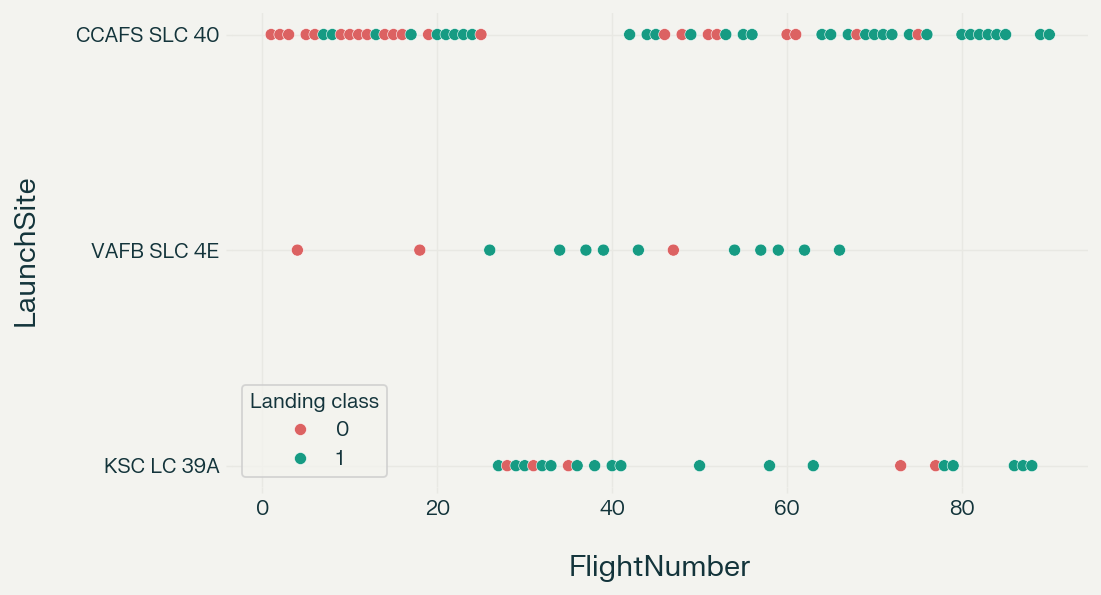

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_18.png'))

## Slide 19: generated figure

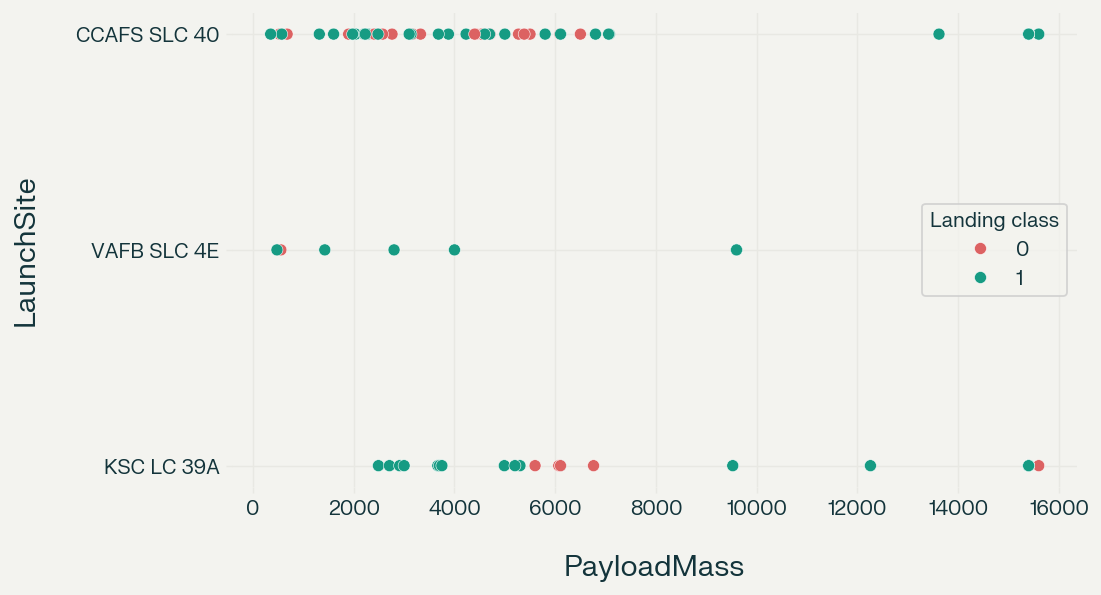

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_19.png'))

## Slide 21: generated figure

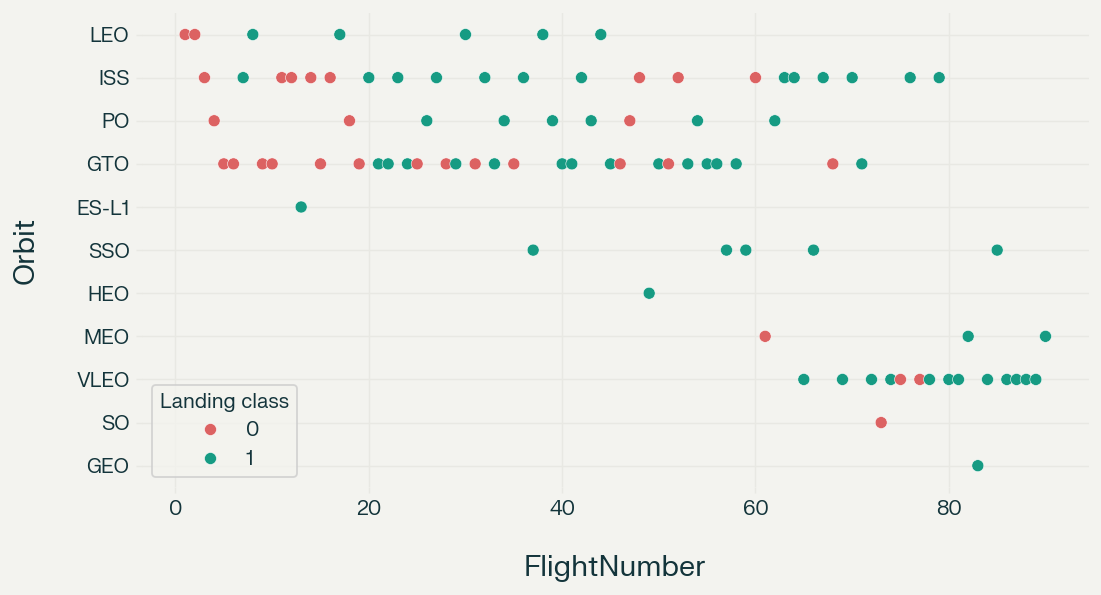

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_21.png'))

## Slide 22: generated figure

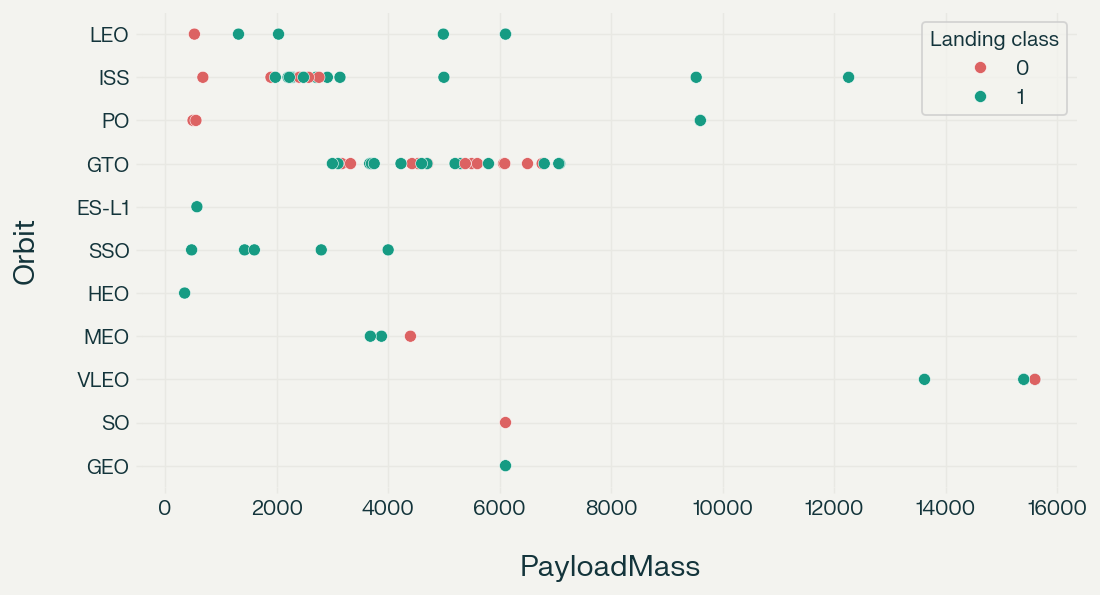

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_22.png'))

## Slide 20: generated figure

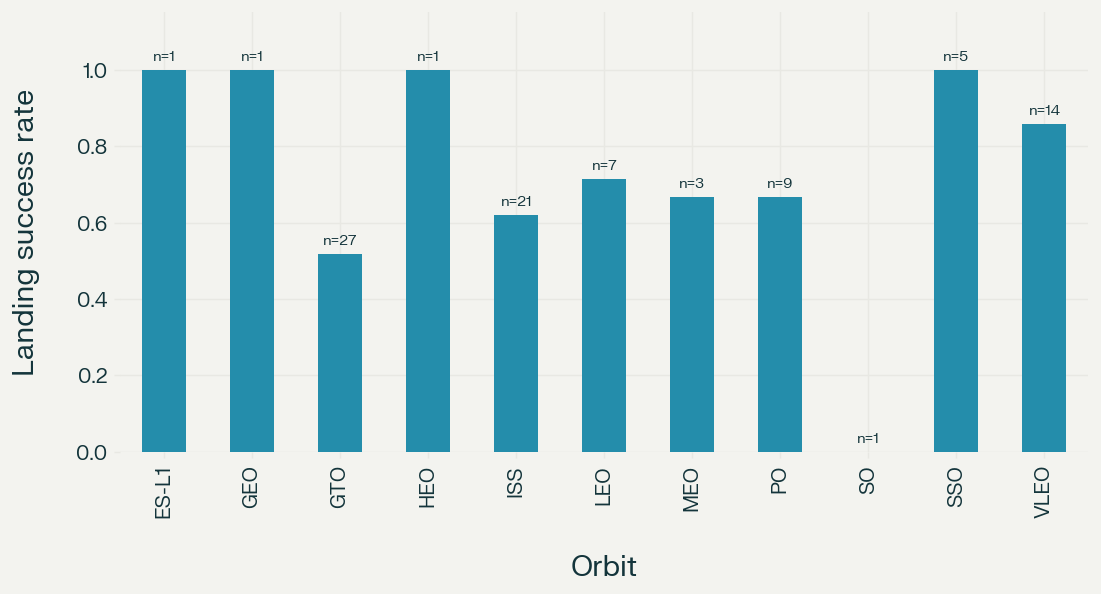

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_20.png'))

## Slide 23: generated figure

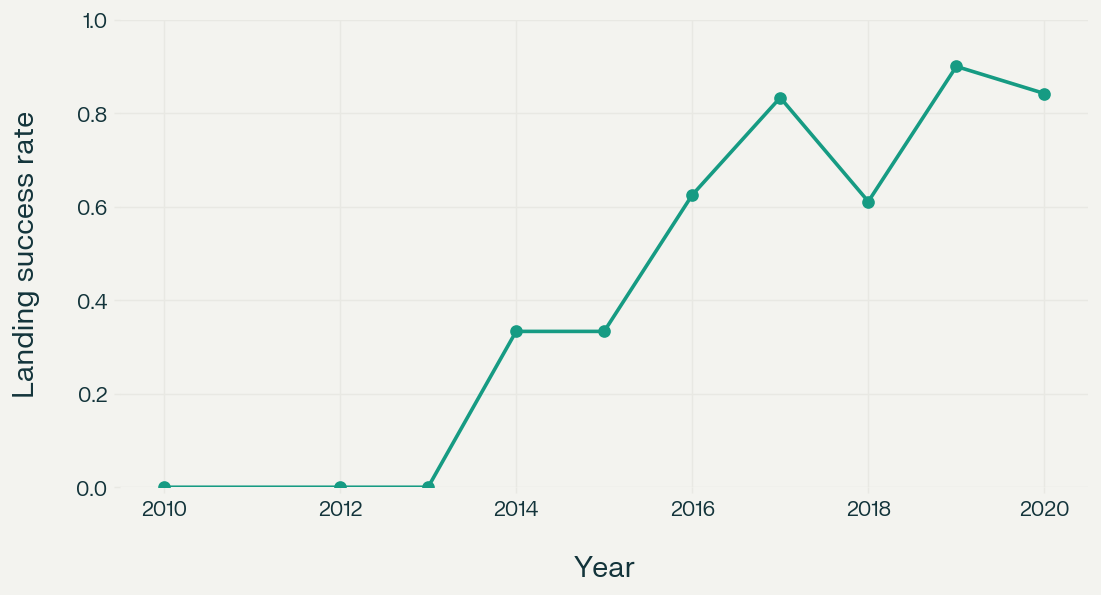

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_23.png'))

## Slide 35: generated figure

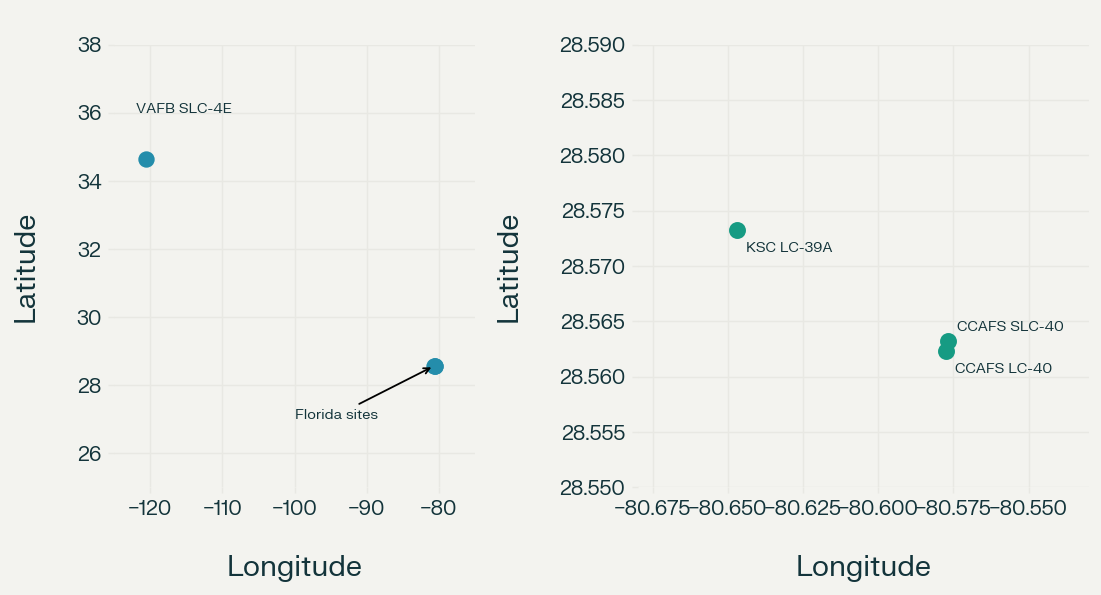

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_35.png'))

## Slide 36: generated figure

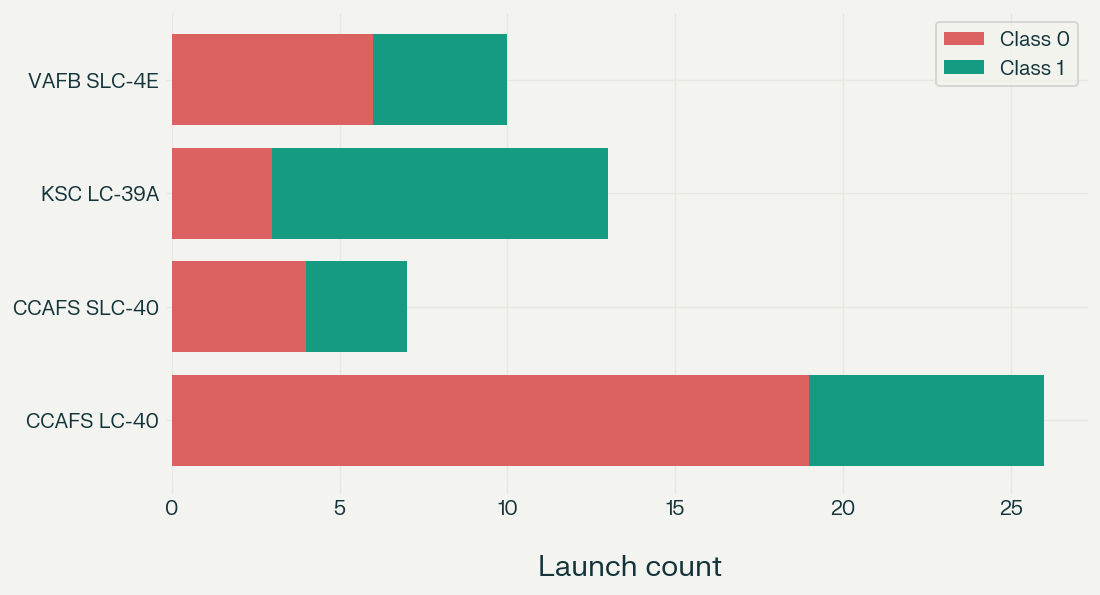

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_36.png'))

## Slide 37: generated figure

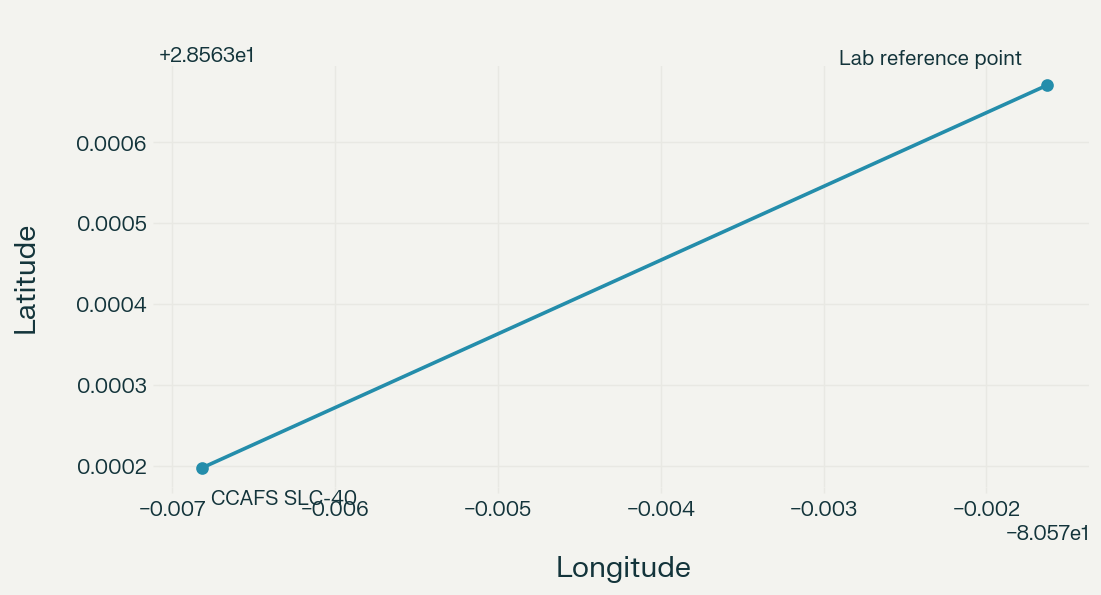

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_37.png'))

## Slide 39: generated figure

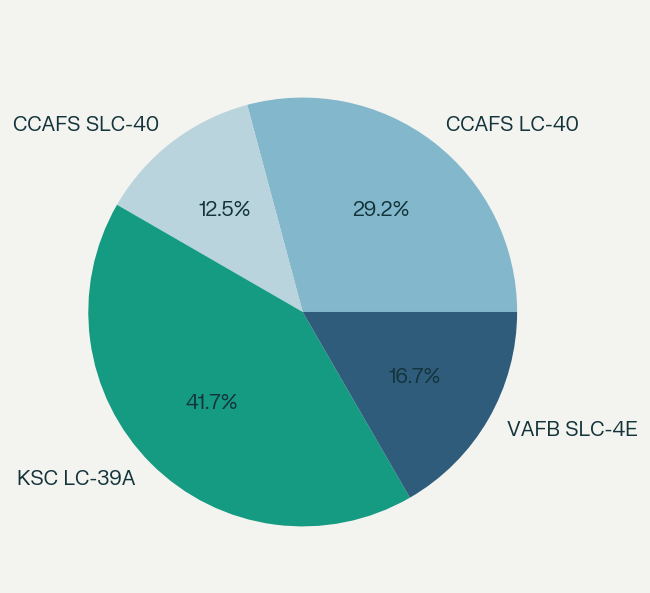

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_39.png'))

## Slide 40: generated figure

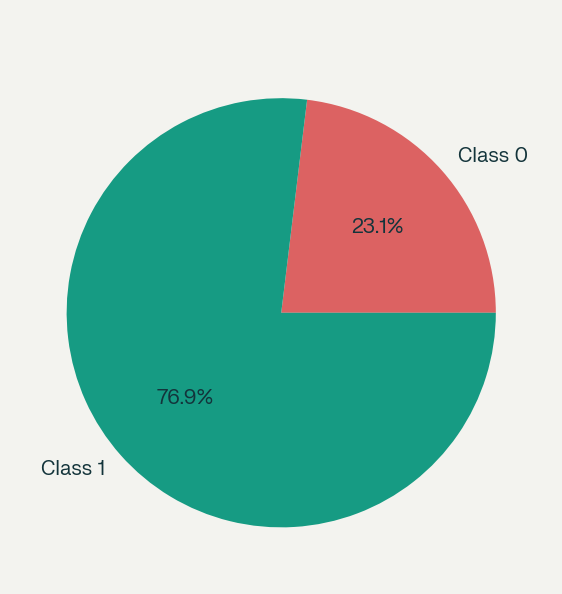

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_40.png'))

## Slide 41: generated figure

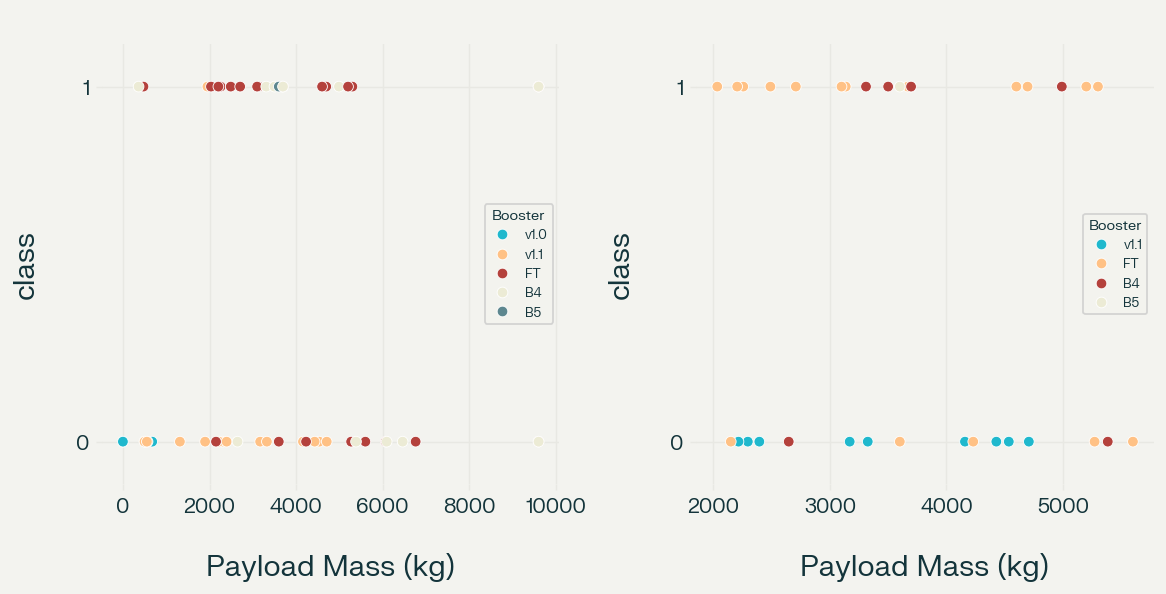

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_41.png'))

## Slide 43: generated figure

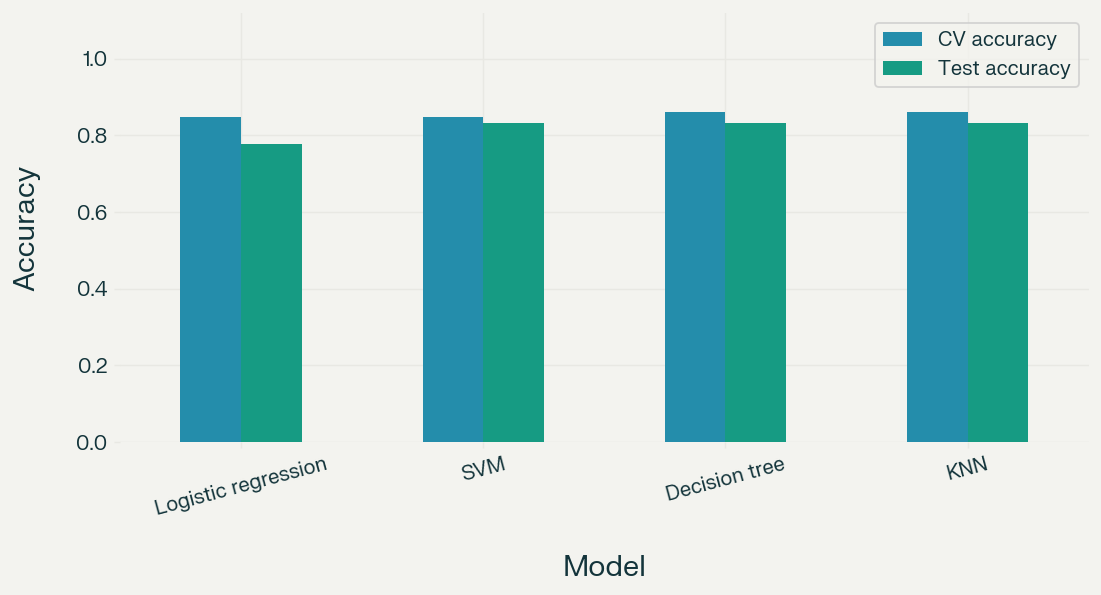

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_43.png'))

## Slide 44: generated figure

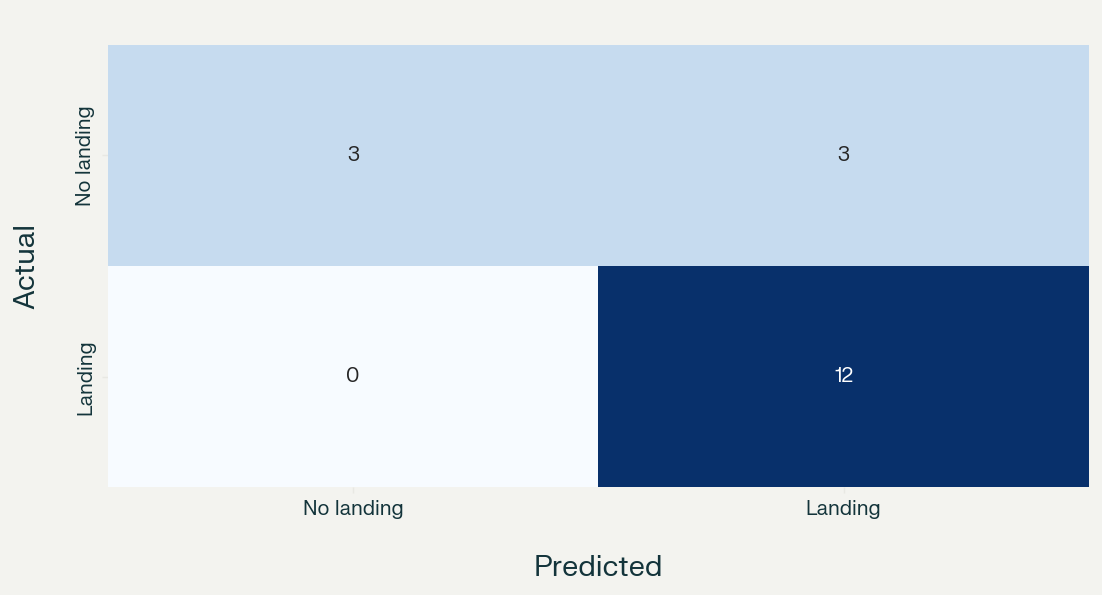

In [ ]:
from IPython.display import Image, display
display(Image(filename='results/slide_44.png'))